In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 6)

df = pd.read_csv("/content/crop_production.csv")
print(df.shape)
df.head()

(15831, 7)


,State_Name,District_Name,Crop_Year,Season,Crop,Area,Production
0,Andaman and Nicobar Islands,NICOBARS,2000.0,Kharif,Arecanut,1254.0,2000.0
1,Andaman and Nicobar Islands,NICOBARS,2000.0,Kharif,Other Kharif pulses,2.0,1.0
2,Andaman and Nicobar Islands,NICOBARS,2000.0,Kharif,Rice,102.0,321.0
3,Andaman and Nicobar Islands,NICOBARS,2000.0,Whole Year,Banana,176.0,641.0
4,Andaman and Nicobar Islands,NICOBARS,2000.0,Whole Year,Cashewnut,720.0,165.0


In [3]:
STATE, CROP, SEASON, YEAR = "State_Name", "Crop", "Season", "Crop_Year"
AREA, PROD = "Area", "Production"
if "yield" not in df.columns:
    df["yield"] = df[PROD] / df[AREA]
df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=[AREA, PROD, "yield"])
num_cols = [c for c in [YEAR, AREA, PROD, "yield"] if c in df.columns]
print("Variables analysed:", num_cols)

Variables analysed: ['Crop_Year', 'Area', 'Production', 'yield']


In [4]:
desc = df[num_cols].describe().T
desc["median"] = df[num_cols].median()
desc["mode"] = df[num_cols].mode().iloc[0]
desc["variance"] = df[num_cols].var()
desc["range"] = desc["max"] - desc["min"]
desc["IQR"] = desc["75%"] - desc["25%"]
desc["CV_%"] = (desc["std"] / desc["mean"]) * 100
desc["skewness"] = df[num_cols].skew()
desc["kurtosis"] = df[num_cols].kurt()
desc = desc.round(2)
desc.to_csv("descriptive_statistics.csv")
desc

,count,mean,std,min,25%,50%,75%,max,median,mode,variance,range,IQR,CV_%,skewness,kurtosis
Crop_Year,15760.0,2006.07,5.13,1997.0,2002.00,2006.00,2011.00,2.014000e+03,2006.00,2013.0,2.629000e+01,1.700000e+01,9.00,0.26,-0.06,-1.21
Area,15760.0,9717.74,37814.87,0.2,127.00,732.00,4017.50,8.770290e+05,732.00,2.0,1.429965e+09,8.770288e+05,3890.50,389.13,11.00,182.03
Production,15760.0,1168657.60,21835977.70,0.0,195.75,1251.00,8794.00,7.801620e+08,1251.00,1.0,4.768099e+14,7.801620e+08,8598.25,1868.47,26.73,784.18
yield,15760.0,150.54,1282.99,0.0,0.60,1.31,4.56,3.308901e+04,1.31,0.5,1.646053e+06,3.308901e+04,3.96,852.25,10.78,138.65


In [5]:
for c in [AREA, PROD, "yield"]:
    print(f"{c}: mean = {df[c].mean():,.1f} | median = {df[c].median():,.1f} | skewness = {df[c].skew():.1f}")

Area: mean = 9,717.7 | median = 732.0 | skewness = 11.0
Production: mean = 1,168,657.6 | median = 1,251.0 | skewness = 26.7
yield: mean = 150.5 | median = 1.3 | skewness = 10.8


In [6]:
by_season = df.groupby(SEASON)[[PROD, "yield"]].agg(["count", "mean", "median", "std"]).round(2)
by_season.to_csv("stats_by_season.csv")
by_season

Production                                   yield                 \
                 count        mean   median          std count    mean median   
Season                                                                          
Autumn             136    19385.32  16546.5     15432.74   136    1.26   1.04   
Kharif            6122    34002.32   1204.0    149662.85  6122    4.00   1.00   
Rabi              4775    21043.24   1000.0     90006.04  4775    2.76   1.00   
Summer             123    30073.97  14971.0     38799.35   123    2.04   2.01   
Whole Year        4475  4042464.52   1262.0  40840128.62  4475  521.62   4.78   
Winter             129   101053.60  92981.0     50357.75   129    1.55   1.53   

                      
                 std  
Season                
Autumn          1.16  
Kharif         11.36  
Rabi            5.42  
Summer          0.77  
Whole Year   2367.58  
Winter          0.41

In [7]:
top5 = df.groupby(CROP)[PROD].sum().sort_values(ascending=False).head(5).index
by_crop = df[df[CROP].isin(top5)].groupby(CROP)["yield"].agg(["count", "mean", "median", "std"]).round(2)
by_crop

,count,mean,median,std
Crop,,,,
Coconut,279,8210.03,8019.92,5190.03
Groundnut,493,1.54,1.39,0.81
Maize,833,3.27,2.20,2.48
Rice,1087,2.07,1.90,1.05
Sugarcane,520,50.00,40.03,31.69


In [8]:
pearson = df[num_cols].corr(method="pearson").round(2)
spearman = df[num_cols].corr(method="spearman").round(2)
print("PEARSON (linear relationship)"); print(pearson)
print("\nSPEARMAN (rank-based, better for skewed data)"); print(spearman)

PEARSON (linear relationship)
            Crop_Year  Area  Production  yield
Crop_Year        1.00 -0.02        0.01   0.03
Area            -0.02  1.00        0.03  -0.01
Production       0.01  0.03        1.00   0.55
yield            0.03 -0.01        0.55   1.00

SPEARMAN (rank-based, better for skewed data)
            Crop_Year  Area  Production  yield
Crop_Year        1.00 -0.04        0.05   0.16
Area            -0.04  1.00        0.83  -0.03
Production       0.05  0.83        1.00   0.48
yield            0.16 -0.03        0.48   1.00


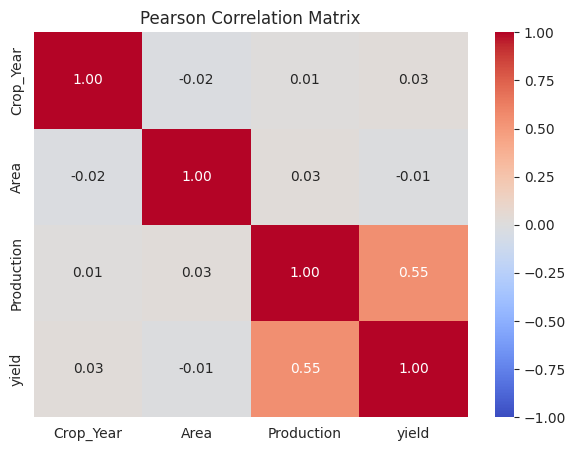

In [9]:
plt.figure(figsize=(7, 5))
sns.heatmap(pearson, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Pearson Correlation Matrix")
plt.savefig("fig1_pearson_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

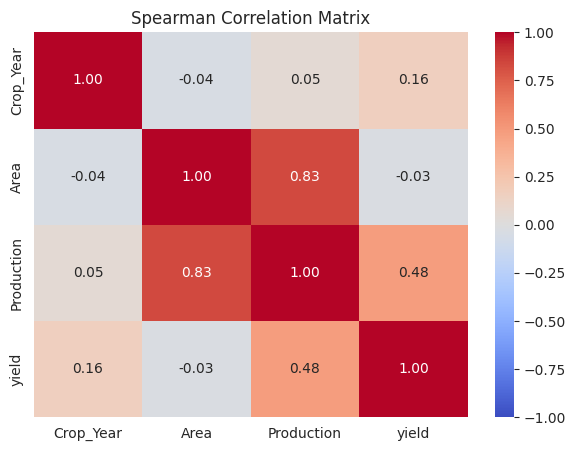

In [10]:
plt.figure(figsize=(7, 5))
sns.heatmap(spearman, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Spearman Correlation Matrix")
plt.savefig("fig2_spearman_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
r, p = stats.pearsonr(df[AREA], df[PROD])
rho, p2 = stats.spearmanr(df[AREA], df[PROD])
lr, lp = stats.pearsonr(np.log1p(df[AREA]), np.log1p(df[PROD]))
print(f"Pearson r (raw)        = {r:.3f}, p-value = {p:.4g}")
print(f"Spearman rho           = {rho:.3f}, p-value = {p2:.4g}")
print(f"Pearson r (log values) = {lr:.3f}, p-value = {lp:.4g}")
print("R-squared (log values) =", round(lr**2, 3))

Pearson r (raw)        = 0.032, p-value = 7.138e-05
Spearman rho           = 0.829, p-value = 0
Pearson r (log values) = 0.804, p-value = 0
R-squared (log values) = 0.646


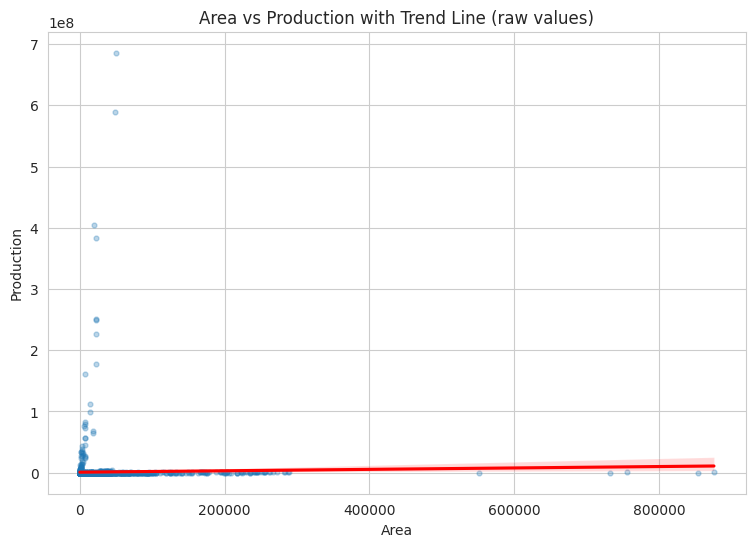

In [12]:
sample = df.sample(min(5000, len(df)), random_state=1)
plt.figure()
sns.regplot(data=sample, x=AREA, y=PROD, scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "red"})
plt.title("Area vs Production with Trend Line (raw values)")
plt.savefig("fig3_scatter_raw.png", dpi=150, bbox_inches="tight")
plt.show()

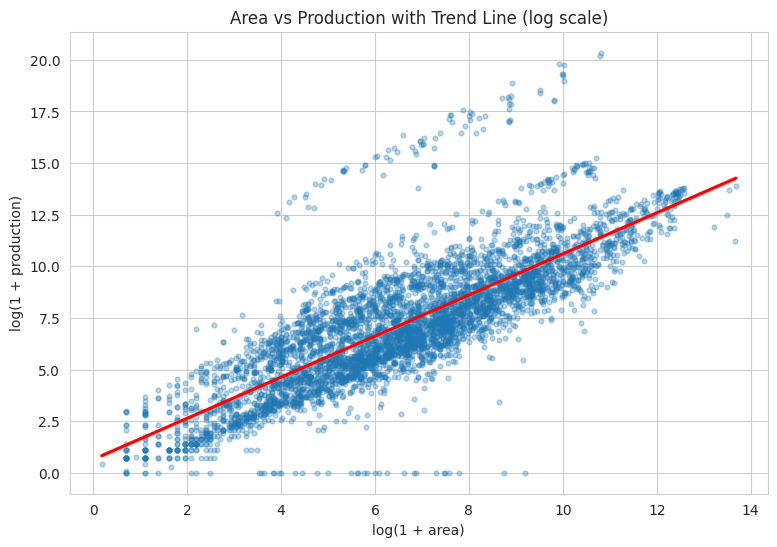

In [13]:
plt.figure()
sns.regplot(x=np.log1p(sample[AREA]), y=np.log1p(sample[PROD]), scatter_kws={"alpha": 0.3, "s": 12}, line_kws={"color": "red"})
plt.title("Area vs Production with Trend Line (log scale)")
plt.xlabel("log(1 + area)"); plt.ylabel("log(1 + production)")
plt.savefig("fig4_scatter_log.png", dpi=150, bbox_inches="tight")
plt.show()

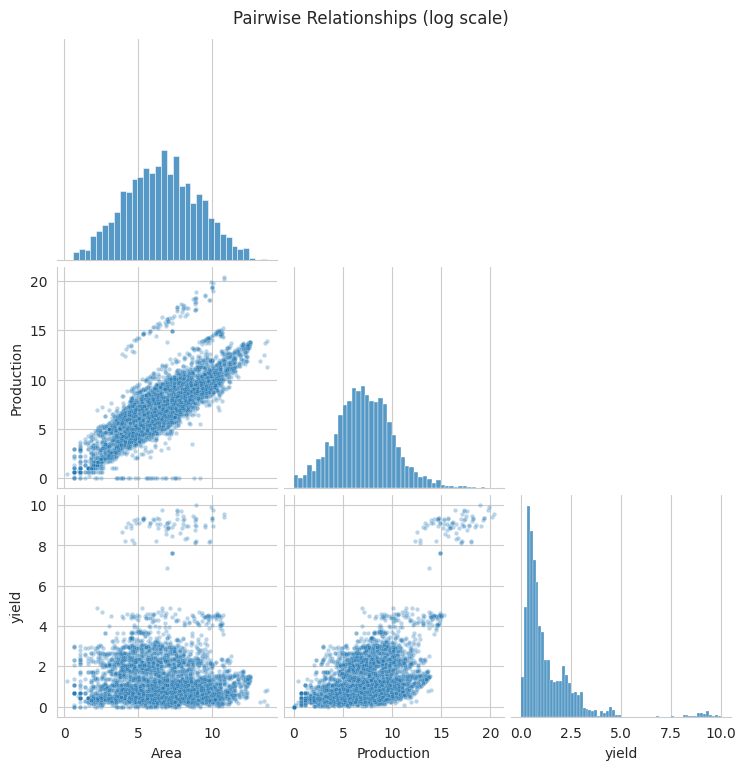

In [14]:
pp = sns.pairplot(sample[[AREA, PROD, "yield"]].apply(np.log1p), corner=True, plot_kws={"alpha": 0.3, "s": 10})
pp.fig.suptitle("Pairwise Relationships (log scale)", y=1.02)
pp.savefig("fig5_pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
groups = [g["yield"].values for _, g in df.groupby(SEASON) if len(g) > 10]
h, pk = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h:.2f}, p-value = {pk:.4g}")
print("Significant difference between seasons" if pk < 0.05 else "No significant difference between seasons")

Kruskal-Wallis H = 1935.70, p-value = 0
Significant difference between seasons


/tmp/ipykernel_648/294637376.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df["yield"] <= cap], x=SEASON, y="yield", palette="Set2")


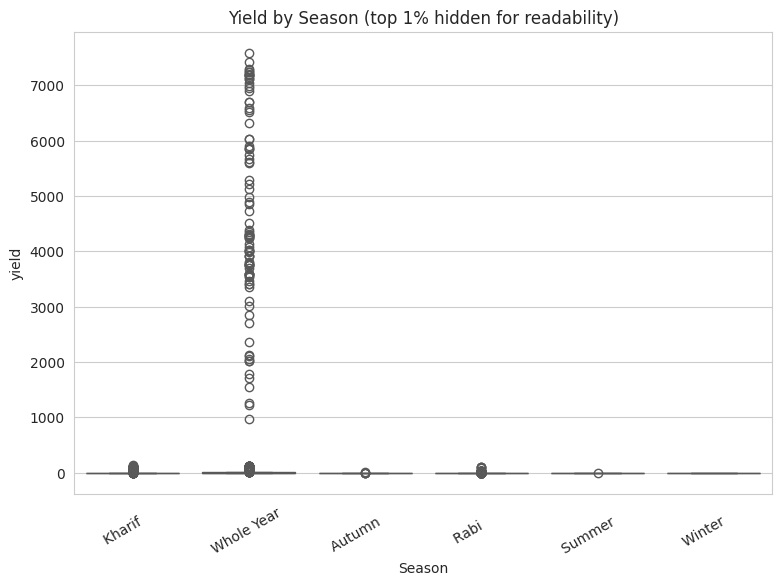

In [16]:
plt.figure()
cap = df["yield"].quantile(0.99)
sns.boxplot(data=df[df["yield"] <= cap], x=SEASON, y="yield", palette="Set2")
plt.title("Yield by Season (top 1% hidden for readability)")
plt.xticks(rotation=30)
plt.savefig("fig6_season_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
print("Rows analysed:", len(df))
print("Strongest Pearson pair (excluding self):")
pr = pearson.where(~np.eye(len(pearson), dtype=bool)).abs().stack().sort_values(ascending=False)
print(pr.head(2))
print("\nMean vs median of production:", round(df[PROD].mean(), 1), "vs", round(df[PROD].median(), 1))

Rows analysed: 15760
Strongest Pearson pair (excluding self):
Production  yield         0.55
yield       Production    0.55
dtype: float64

Mean vs median of production: 1168657.6 vs 1251.0
